In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

### **Data Loading**


In [4]:
data = pd.read_csv("/content/marketing_campaign.csv",sep="\t")
data

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [7]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [5]:
data.shape


(2240, 29)

In [6]:
data.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

**Data Types**

In [8]:
data.dtypes

,0
ID,int64
Year_Birth,int64
Education,object
Marital_Status,object
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,object
Recency,int64
MntWines,int64


**Data Info**

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

**Statistical Description**

In [10]:
data.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [11]:
data.describe(include="object")

,Education,Marital_Status,Dt_Customer
count,2240,2240,2240
unique,5,8,663
top,Graduation,Married,31-08-2012
freq,1127,864,12


**Unique Values**

In [12]:
data["Marital_Status"].value_counts()

,count
Marital_Status,
Married,864
Together,580
Single,480
Divorced,232
Widow,77
Alone,3
Absurd,2
YOLO,2


In [13]:
data["Education"].value_counts()


,count
Education,
Graduation,1127
PhD,486
Master,370
2n Cycle,203
Basic,54


**Missing Values**

In [14]:
data.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [15]:
(data.isnull().sum() / len(data)) * 100

,0
ID,0.000000
Year_Birth,0.000000
Education,0.000000
Marital_Status,0.000000
Income,1.071429
Kidhome,0.000000
Teenhome,0.000000
Dt_Customer,0.000000
Recency,0.000000
MntWines,0.000000


عمود الدخل يحتوي على 24 قيمة مفقودة بنسبة %1.07



**Duplicate Rows**

In [16]:
data.duplicated().sum()

np.int64(0)

**clean data**

In [18]:
cleaned_data = data.copy()
cleaned_data

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


**Handling Missing Values**

In [20]:
cleaned_data["Income"] = cleaned_data["Income"].fillna(cleaned_data["Income"].median())
cleaned_data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [21]:
cleaned_data["Income"].isnull().sum()

np.int64(0)

**Date Conversion**

In [22]:
cleaned_data["Dt_Customer"] = pd.to_datetime(cleaned_data["Dt_Customer"], format="%d-%m-%Y")
cleaned_data["Dt_Customer"].dtype

dtype('<M8[ns]')

**Invalid Values**

In [23]:
print("Min:", cleaned_data["Year_Birth"].min())
print("Max:", cleaned_data["Year_Birth"].max())

Min: 1893
Max: 1996


In [24]:
cleaned_data[cleaned_data["Year_Birth"] < 1920]["Year_Birth"]

,Year_Birth
192,1900
239,1893
339,1899


فحصت سنة الميلاد للعملاء، ولقيت 3 أشخاص مسجلين بسنوات ميلاد قديمة كثير (1893 و1899 و1900)، فقررت استبعدهم من البيانات اللي بنظفها لأن أعمارهم غير معتادة جدًا وممكن تكون ناتجة عن أخطاء في إدخال البيانات.

In [25]:
cleaned_data = cleaned_data[cleaned_data["Year_Birth"] >= 1920].copy()
cleaned_data.shape

(2237, 29)

In [26]:
cleaned_data["Marital_Status"] = cleaned_data["Marital_Status"].replace({
    "Alone": "Single",
    "Absurd": "Unknown",
    "YOLO": "Unknown"
})

cleaned_data["Marital_Status"].value_counts()

,count
Marital_Status,
Married,864
Together,579
Single,482
Divorced,231
Widow,77
Unknown,4


**Outliers**

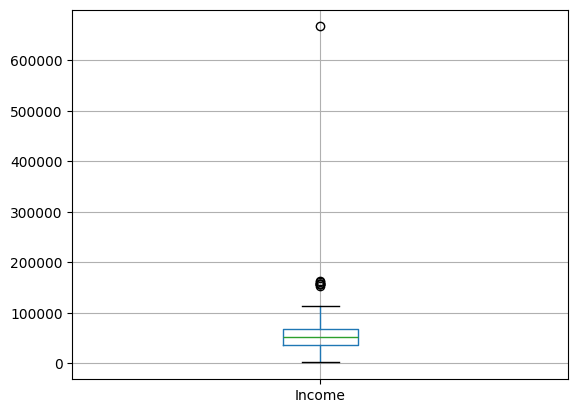

In [27]:
cleaned_data.boxplot(column="Income")
plt.show()

**IQR**

In [28]:
Q1 = cleaned_data["Income"].quantile(0.25)
Q3 = cleaned_data["Income"].quantile(0.75)

IQR = Q3 - Q1

print("Lower limit:", Q1 - 1.5 * IQR)
print("Upper limit:", Q3 + 1.5 * IQR)

Lower limit: -13614.0
Upper limit: 117418.0


In [29]:
upper_limit = Q3 + 1.5 * IQR

outliers = cleaned_data[cleaned_data["Income"] > upper_limit]

print("Number of outliers:", len(outliers))
outliers["Income"].sort_values(ascending=False)

Number of outliers: 8


,Income
2233,666666.0
617,162397.0
687,160803.0
1300,157733.0
164,157243.0
1653,157146.0
2132,156924.0
655,153924.0


In [30]:
cleaned_data.loc[2233]

,2233
ID,9432
Year_Birth,1977
Education,Graduation
Marital_Status,Together
Income,666666.0
Kidhome,1
Teenhome,0
Dt_Customer,2013-06-02 00:00:00
Recency,23
MntWines,9


In [31]:
cleaned_data = cleaned_data[cleaned_data["Income"] != 666666].copy()

cleaned_data.shape

(2236, 29)

شلت السجل اللي دخله 666666 لأنه بعيد جدًا عن باقي القيم، وخلّيت بقية البيانات زي ما هي.

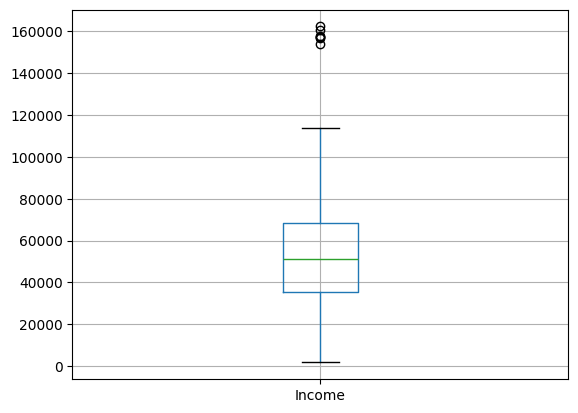

In [32]:
cleaned_data.boxplot(column="Income")
plt.show()

**Histogram**

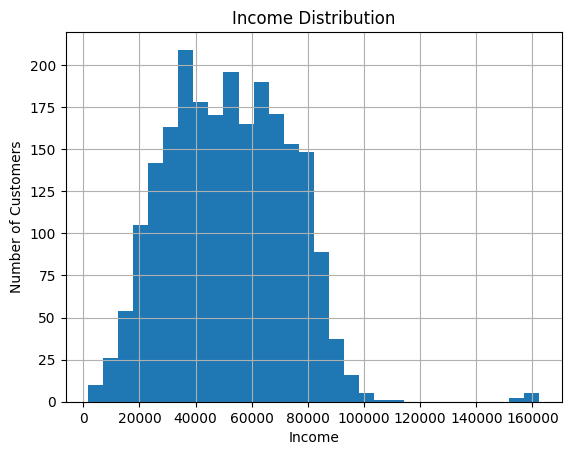

In [33]:
cleaned_data["Income"].hist(bins=30)
plt.xlabel("Income")
plt.ylabel("Number of Customers")
plt.title("Income Distribution")
plt.show()

لاحظت إنه أغلب العملاء دخلهم متوسط، تقريبًا بين 20 ألف و80 ألف، وفي عدد قليل جدًا عندهم دخل عالي. وهيك قدرت افهم توزيع الدخل بعد ما نظفت البيانات.

In [34]:
print("Shape:", cleaned_data.shape)
print("Missing values:", cleaned_data.isnull().sum().sum())

Shape: (2236, 29)
Missing values: 0


In [35]:
cleaned_data.to_csv("marketing_campaign_cleaned.csv", index=False)

بعد ما خلصت تنظيف البيانات وتأكدت إنه ما في قيم ناقصة،
حفظت النسخة المنظّفة
 بملف CSV جديد، مع الاحتفاظ بالملف الأصلي زي ما هو.

**Encoding**

In [36]:
cleaned_data.select_dtypes(include="object").columns

Index(['Education', 'Marital_Status'], dtype='object')

In [37]:
model_data = cleaned_data.copy()

model_data["Customer_Year"] = model_data["Dt_Customer"].dt.year
model_data["Customer_Month"] = model_data["Dt_Customer"].dt.month

model_data = model_data.drop(columns=["Dt_Customer"])

model_data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Customer_Year,Customer_Month
0,5524,1957,Graduation,Single,58138.0,0,0,58,635,88,...,0,0,0,0,0,3,11,1,2012,9
1,2174,1954,Graduation,Single,46344.0,1,1,38,11,1,...,0,0,0,0,0,3,11,0,2014,3
2,4141,1965,Graduation,Together,71613.0,0,0,26,426,49,...,0,0,0,0,0,3,11,0,2013,8
3,6182,1984,Graduation,Together,26646.0,1,0,26,11,4,...,0,0,0,0,0,3,11,0,2014,2
4,5324,1981,PhD,Married,58293.0,1,0,94,173,43,...,0,0,0,0,0,3,11,0,2014,1


In [38]:
X = model_data.drop(columns=["ID", "Response"])
y = model_data["Response"]

print("X:", X.shape)
print("y:", y.shape)

X: (2236, 28)
y: (2236,)


**Train/Test Split**

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (1788, 28)
Testing: (448, 28)


In [40]:
education_order = {
    "Basic": 0,
    "2n Cycle": 1,
    "Graduation": 2,
    "Master": 3,
    "PhD": 4
}

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Education"] = X_train["Education"].map(education_order)
X_test["Education"] = X_test["Education"].map(education_order)

X_train["Education"].value_counts()

,count
Education,
2,898
4,380
3,308
1,155
0,47


In [41]:
X_train = pd.get_dummies(X_train, columns=["Marital_Status"], dtype=int)

X_test = pd.get_dummies(X_test, columns=["Marital_Status"], dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (1788, 33)
Testing: (448, 33)


In [42]:
print("Missing in Training:", X_train.isnull().sum().sum())
print("Missing in Testing:", X_test.isnull().sum().sum())

print("Text columns:", X_train.select_dtypes(include="object").columns)

Missing in Training: 0
Missing in Testing: 0
Text columns: Index([], dtype='object')


**StandardScaler **

In [43]:
from sklearn.preprocessing import StandardScaler

scale_cols = [
    col for col in X_train.columns
    if X_train[col].nunique() > 2 and col != "Education"
]

scaler = StandardScaler()

X_train_standard = X_train.copy()
X_test_standard = X_test.copy()

X_train_standard[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_standard[scale_cols] = scaler.transform(X_test[scale_cols])

X_train_standard[["Income", "Recency"]].head()

,Income,Recency
1648,0.243739,-1.071017
403,-1.006680,-0.690677
1522,-0.669059,1.141871
1815,-1.413657,1.072718
660,0.202276,1.176447


**MinMaxScaler**

In [44]:
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()

X_train_minmax = X_train.copy()
X_test_minmax = X_test.copy()

X_train_minmax[scale_cols] = minmax_scaler.fit_transform(X_train[scale_cols])
X_test_minmax[scale_cols] = minmax_scaler.transform(X_test[scale_cols])

X_train_minmax[["Income", "Recency"]].head()

,Income,Recency
1648,0.341913,0.181818
403,0.175430,0.292929
1522,0.220381,0.828283
1815,0.121244,0.808081
660,0.336393,0.838384


In [45]:
comparison = pd.DataFrame({
    "Original": X_train["Income"].head().values,
    "StandardScaler": X_train_standard["Income"].head().values,
    "MinMaxScaler": X_train_minmax["Income"].head().values
})

comparison

,Original,StandardScaler,MinMaxScaler
0,57136.0,0.243739,0.341913
1,30507.0,-1.006680,0.175430
2,37697.0,-0.669059,0.220381
3,21840.0,-1.413657,0.121244
4,56253.0,0.202276,0.336393


In [46]:
from google.colab import files

files.download("marketing_campaign_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>